# What one view can tell us about a potato
**CSE527 · Potato3D research results · November 2026**

A conveyor camera sees the top of a potato. This project tested what we can infer about the hidden underside, whether a small color change can move the predicted surface, and whether a second frame is worth the cost.

| Research question | What we found |
|---|---|
| Can we recover the hidden underside from depth? | Local repair helped with isolated synthetic spikes. Regional reflection and a scan-only height correction did not establish an accuracy gain on separate potato cohorts. |
| Does a registration pin affect CoRe++? | On 29 previously unscored potatoes, pin recoloring moved the prediction **0.494 mm farther** than matched peel edits on average. Five acquisition groups make this descriptive under the frozen rule. |
| Does a second frame help estimate volume? | Averaging two frames reduced mean absolute volume error from **29.92 to 28.48 mL** on ten development potatoes. The two tested rescan screens did not beat random selection. |
| Does a second RGB model behave the same way? | On the same one-frame pilot, **TripoSR moved farther for the peel edit**. CoRe++ moved farther for the pin edit. |

**How to present this notebook.** Scroll through the saved figures and short interpretations. The appendix contains the detailed tables and links. Run all cells from this checkout to regenerate the displays using the archived summaries and tables.

In [1]:
import csv
import io
import json
from html import escape
from pathlib import Path
from statistics import mean

import matplotlib.pyplot as plt
from IPython.display import HTML, Image, display
from PIL import Image as PILImage

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents)
            if (path / "studies/regional_shape_v1/triposr_pin_pilot/results.json").is_file())
STUDY = "studies/regional_shape_v1/"
INK = "#23323A"
TEAL = "#147E77"
ORANGE = "#BA593B"
GRAY = "#6F7B82"
LINE = "#D9E1E4"

plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 11, "axes.spines.top": False,
    "axes.spines.right": False, "axes.edgecolor": LINE, "axes.labelcolor": INK,
    "axes.titlecolor": INK, "text.color": INK, "xtick.color": INK, "ytick.color": INK,
    "figure.facecolor": "white", "savefig.facecolor": "white",
})


def result(name):
    return json.loads((ROOT / (STUDY + name)).read_text())


def records(path):
    with (ROOT / path).open(newline="") as stream:
        return list(csv.DictReader(stream))


def archived_figure(path, alt, max_width=1060):
    with PILImage.open(ROOT / path) as source:
        img = source.copy()
    img.thumbnail((max_width, 2000), PILImage.Resampling.LANCZOS)
    out = io.BytesIO()
    img.save(out, format="PNG", optimize=True)
    display(Image(data=out.getvalue(), format="png", width=img.width, alt=alt))


def plot(fig, alt):
    out = io.BytesIO()
    fig.savefig(out, format="png", dpi=128, bbox_inches="tight", pad_inches=.16)
    plt.close(fig)
    display(Image(data=out.getvalue(), format="png", alt=alt))


def compact_table(headers, rows, folded=None):
    heading = "".join(f"<th scope='col'>{escape(str(h))}</th>" for h in headers)
    body = []
    for index, row in enumerate(rows):
        shade = "#F4F7F7" if index % 2 == 0 else "white"
        data = "".join(f"<td>{escape(str(value))}</td>" for value in row)
        body.append(f"<tr style='background:{shade}'>{data}</tr>")
    table = (f"<table style='border-collapse:collapse;margin:.65em 0'><thead><tr>{heading}"
             f"</tr></thead><tbody>{''.join(body)}</tbody></table>")
    if folded:
        table = f"<details><summary><strong>{escape(folded)}</strong></summary>{table}</details>"
    display(HTML(table))


def signed_bars(ax, labels, values, xlabel):
    colors = [TEAL if v < 0 else ORANGE for v in values]
    ax.barh(labels, values, color=colors, height=.65)
    ax.invert_yaxis()
    ax.axvline(0, color=INK, linewidth=.9)
    ax.grid(axis="x", alpha=.30)
    ax.set_axisbelow(True)
    ax.set_xlabel(xlabel)

## 1. What can we infer about the hidden surface?

We implemented and checked a CPU geometry pipeline with three simple baselines that fit an ellipsoid, wrap the visible points in a convex hull, or mirror the visible surface. A five-potato public demo checked data, units and registration. Synthetic shapes let us isolate depth errors because their full surfaces are known.

| Experiment | Result |
|---|---|
| Height robustness | A 95th-percentile height estimate with cap clipping improved the predefined outlier comparisons on **12 synthetic development families**. |
| Local depth repair | Passed **5 of 5** checks on **12 fresh synthetic families**. It removed isolated spikes and preserved clean observations. Its error rose on coherent patches. |
| Wider annular repair | Passed **5 of 7** checks. It helped with coherent artifacts but erased genuine narrow features and missed the required bound against the clipped percentile baseline. |
| Body plus visible detail | Passed **4 of 5** checks on **24 synthetic confirmation families**. It struggled when a real feature continued onto the underside. |
| Laboratory peppers | All **24 development and 72 local-holdout** predictions succeeded. Training templates had the best descriptive scores. The fitted ellipsoid's F5 uncertainty interval crossed zero. |

A raised artifact at the top moved the ordinary mirror's distant underside by **5.63 mm**. When we held its mirror height at the clean-scan value, the movement fell to **0.00 mm**. The clean height is available in this controlled diagnostic. In a real scan, an artifact and a genuine lobe can look alike from above.

[Course report](course/REPORT.md) · [Local repair](docs/spatial_confidence_report.md) · [Annular repair](docs/multiscale_confidence_report.md) · [Body and detail](studies/body_detail_v1/results.md) · [Bonn pepper holdout](docs/bonn_real_v1_report.md)

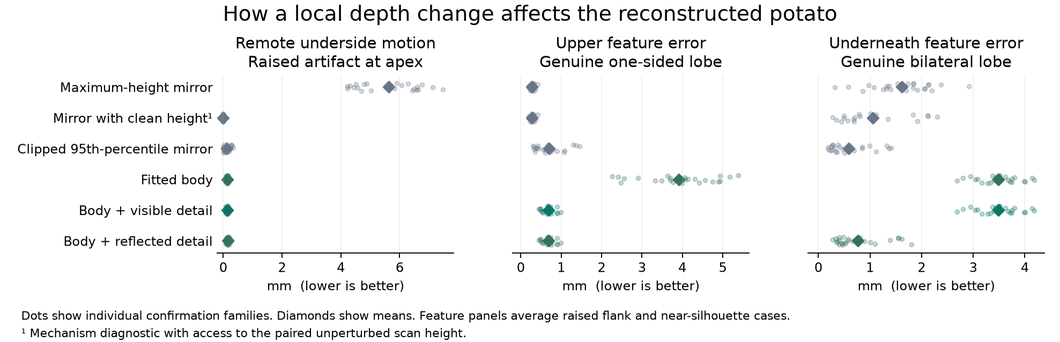

In [2]:
archived_figure("studies/body_detail_v1/confirmation.png",
                "Synthetic body and detail results showing how mirror height can move the hidden surface")

## 2. Did the geometry ideas transfer to real potatoes?

A real-data pilot found **0 of 12** tubers with both a reference-corroborated lobe and an eligible within-tuber control under the frozen screening rules. We then measured broader underside regions. Seven of the twelve development potatoes passed coverage and supplied measurable regions.

Full-strength reflection increased mean underside error from **5.512 to 5.729 mm**. Selecting the strength using the other tubers lowered the development mean to **5.413 mm**, a small gain that did not carry over to a fixed quarter-strength replication. A vertical-shift diagnostic showed more room for improvement. The version that estimated height from the RGB-D scan helped on development data, but its separate confirmation interval included zero.

[Real-lobe screening](studies/real_lobes_v1/fresh_pilot_report.md) · [Regional development](studies/regional_shape_v1/results.md) · [Reflection selection](studies/regional_shape_v1/reflection_weight_report.md) · [Replication](studies/regional_shape_v1/replication_report.md)

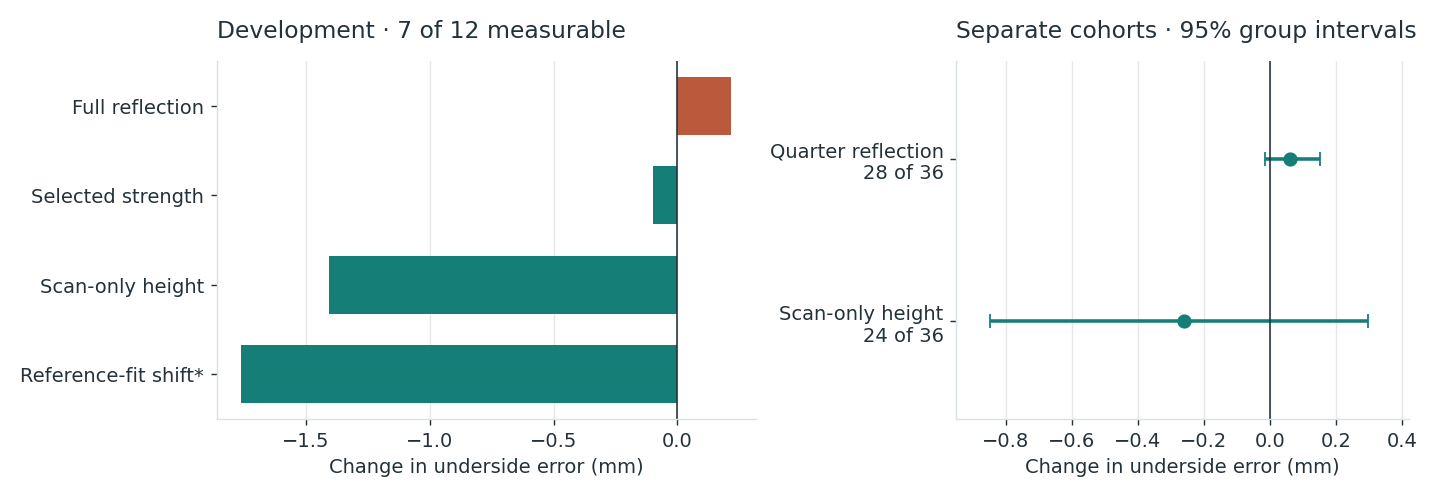

In [3]:
regional = result("results.json")["summary"]
reflection = result("reflection_weight_results.json")["out_of_fold_scores_mm"]
vertical = result("vertical_offset_results.json")["equal_tuber_mean_mm"]
support = result("support_offset_results.json")
replication = result("replication_results.json")["summary"]
confirmation = result("support_offset_confirmation_results.json")["summary"]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.65), layout="constrained",
                         gridspec_kw={"width_ratios": [1.19, 1]})
signed_bars(axes[0], ["Full reflection", "Selected strength", "Scan-only height", "Reference-fit shift*"],
            [regional["errors_mm"]["aligned_minus_body"], reflection["aligned_minus_body"],
             support["equal_tuber_change_mm"], vertical["held_out_change_mm"]],
            "Change in underside error (mm)")
axes[0].set_title("Development · 7 of 12 measurable", loc="left", pad=13)
axes[0].set_xticks([-1.5, -1, -.5, 0])

ax = axes[1]
settings = [
    ("Quarter reflection\n28 of 36", replication["primary"]["mean_delta_mm"], replication["primary"]),
    ("Scan-only height\n24 of 36", confirmation["primary"]["scores_mm"]["shifted_minus_body"], confirmation["primary"]),
]
for y, (label, value, stats) in enumerate(settings):
    low, high = stats["group_percentile_95_mm"]
    ax.errorbar(value, y, xerr=[[value-low], [high-value]], fmt="o", color=TEAL,
                markersize=7, linewidth=2, capsize=4)
ax.set_yticks(range(len(settings)), [row[0] for row in settings])
ax.invert_yaxis()
ax.set_ylim(1.6, -.6)
ax.set_xlim(-.95, .42)
ax.axvline(0, color=INK, linewidth=.9)
ax.grid(axis="x", alpha=.30)
ax.set_xlabel("Change in underside error (mm)")
ax.set_title("Separate cohorts · 95% group intervals", loc="left", pad=13)
plot(fig, "Changes in underside error on development potatoes and two separate cohorts")

*Negative values mean lower error. The reference-fit shift used alternating sectors of the reference and evaluated the other sectors. It was a diagnostic.*

The fixed height correction reduced mean error by **0.262 mm** on the 24 measurable confirmation potatoes. The 95% acquisition-group interval was **−0.847 to +0.295 mm**. Within nine groups, correctly matched shifts scored **5.028 mm** versus **5.155 mm** for within-group reassignment. The calibration audit found no independent measurement of the physical support height under a potato at capture time.

[Vertical shift diagnostic](studies/regional_shape_v1/vertical_offset_report.md) · [Scan-only development and shuffled control](studies/regional_shape_v1/support_offset_report.md) · [Support-height confirmation](studies/regional_shape_v1/support_offset_confirmation_report.md) · [Calibration audit](studies/regional_shape_v1/calibration_data_audit.md)

## 3. Did changing pin color move the CoRe++ prediction?

We changed only RGB. Each pin edit and three peel edits used the same realized pixel changes. Depth and the crop were held fixed, and dropout was paired across 16 seeds. The one-frame pilot favored the pin in every seed pair. The 10-potato development experiment favored the pin on **9 of 10** potatoes. Expanding the extraction grid from 20³ to 30³ kept all ten contrast signs and reduced boundary contact from **321 of 800 meshes to zero**.

The separate 29-potato cohort used objects in the released model’s test split that were fresh to this experiment. The strongest-peel control compares the pin with the peel patch having the largest median displacement for that potato.

[CPU and pin-preprocessing audit](studies/regional_shape_v1/corepp_cpu_audit.md) · [One-frame pilot](studies/regional_shape_v1/corepp_pin_pilot/report.md) · [Development study](studies/regional_shape_v1/corepp_pin_multituber/report.md) · [Grid check](studies/regional_shape_v1/corepp_pin_grid_boundary/report.md) · [Fresh-potato study](studies/regional_shape_v1/corepp_pin_confirmation/report.md)

Pin compared with,Mean contrast (mm),95% group interval (mm),Positive / tied / negative
Mean of three peel patches,+0.4941,+0.3089 to +0.6271,25 / 1 / 3
Strongest fixed peel patch,+0.3976,+0.2267 to +0.4956,24 / 2 / 3


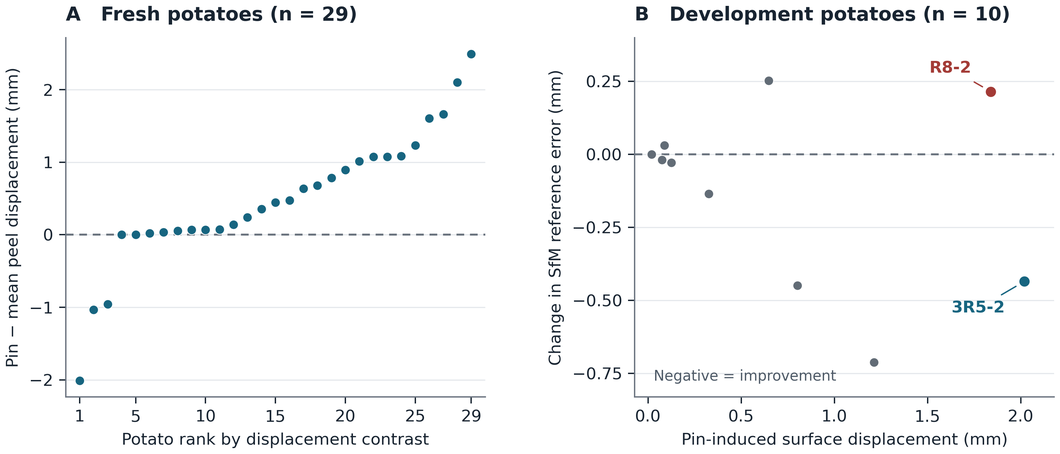

In [4]:
fresh = records(STUDY + "corepp_pin_confirmation/per_potato.csv")
fresh_run = result("corepp_pin_confirmation/results.json")
fresh_summary = fresh_run["summary"]
fresh_rows = []
for label, col, key in [
    ("Mean of three peel patches", "primary_mm", "primary"),
    ("Strongest fixed peel patch", "pin_minus_strongest_mm", "strongest_peel"),
]:
    observed = [float(row[col]) for row in fresh]
    record = fresh_summary[key]
    low, high = record["group_interval_95_mm"]
    assert abs(mean(observed) - record["mean_mm"]) < 1e-10
    fresh_rows.append([label, f"{mean(observed):+.4f}", f"{low:+.4f} to {high:+.4f}",
                       f"{record['positive']} / {record['tied']} / {record['negative']}"])
compact_table(["Pin compared with", "Mean contrast (mm)", "95% group interval (mm)", "Positive / tied / negative"],
              fresh_rows)
archived_figure(STUDY + "corepp_pin_findings.png",
                "Panel A ranks pin-minus-peel on 29 fresh potatoes. Panel B compares movement and reference error on ten development potatoes.")

**A · Sensitivity.** The pin moved predictions farther on most fresh potatoes, even against the strongest peel patch. Both reported group intervals were positive. The evidence is descriptive under the prespecified rule because **five acquisition groups** fell short of the required **six**.

**B · Accuracy.** On the separate ten development potatoes, pin recoloring moved the prediction closer to the reference on **6**, farther on **3**, and tied on **1**. Similar-sized movements could help or hurt. The prediction moved **2.02 mm** on 3R5-2 and reference error fell **0.43 mm**. It moved **1.84 mm** on R8-2 and error rose **0.22 mm**.

[Fresh per-potato data](studies/regional_shape_v1/corepp_pin_confirmation/per_potato.csv) · [Development accuracy](studies/regional_shape_v1/corepp_pin_accuracy/report.md) · [Paper-ready figure and notes](studies/regional_shape_v1/corepp_pin_findings.md)

## 4. Did the sensitivity follow the transplanted pixels?

In a synthetic swap, we exchanged the original pin colors with a peel patch, then recolored each site in the native and swapped layouts. Each displacement was measured from its own unchanged layout. The one-frame pilot switched from the pin site to the peel site after the swap.

Across 10 development potatoes and three peel locations per potato, response shifted toward the transplanted pixels on **9 of 10** potatoes. The average shift was **+1.119 mm**. The more responsive site switched in the pilot direction on at least two patches for **8 of 10**. One additional potato switched in the opposite direction. The result concerns the RGB appearance in these synthetic swaps.

[Swap pilot and crops](studies/regional_shape_v1/corepp_pin_swap_pilot/report.md) · [Ten-potato replication](studies/regional_shape_v1/corepp_pin_swap_replication/report.md)

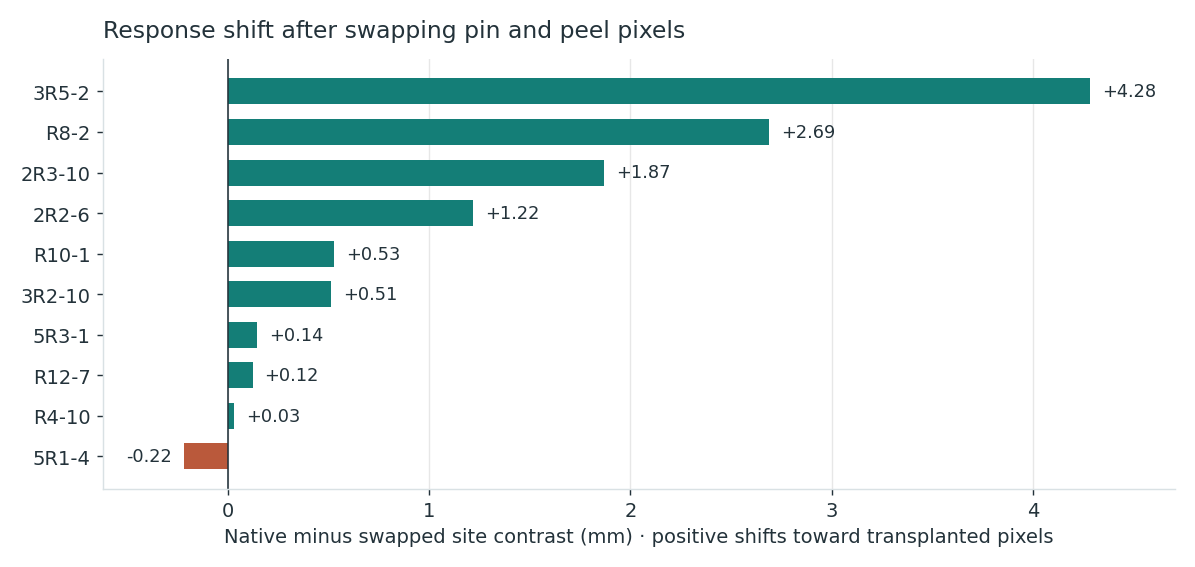

In [5]:
swap = sorted(records(STUDY + "corepp_pin_swap_replication/per_potato.csv"), key=lambda row: float(row["endpoint_mm"]), reverse=True)
values = [float(row["endpoint_mm"]) for row in swap]
fig, ax = plt.subplots(figsize=(9.1, 4.2), layout="constrained")
ax.barh([row["potato"] for row in swap], values,
        color=[TEAL if value > 0 else ORANGE for value in values], height=.64)
ax.invert_yaxis()
ax.axvline(0, c=INK, lw=.9)
ax.grid(axis="x", alpha=.30)
ax.set_axisbelow(True)
ax.set_xlim(-.62, max(values)+.42)
for i, value in enumerate(values):
    offset, alignment = (.06, "left") if value >= 0 else (-.06, "right")
    ax.text(value + offset, i, f"{value:+.2f}", ha=alignment, va="center", color=INK, fontsize=10)
ax.set_title("Response shift after swapping pin and peel pixels", loc="left", pad=12)
ax.set_xlabel("Native minus swapped site contrast (mm) · positive shifts toward transplanted pixels")
plot(fig, "Nine of ten development potatoes shifted sensitivity toward transplanted pixels")

## 5. Did a second conveyor frame improve volume estimates?

A separate practical question was whether to spend a limited budget on a second view. First we checked what would happen if every potato received a second frame. We used the archived predictions from the center frame and a second frame chosen by a fixed quarter-index rule in numerical suffix order. The physical viewing angles are unverified. Drainage measurements supplied the volume reference.

Averaging the predicted volumes lowered mean absolute error from **29.92 to 28.48 mL**. The median paired change was **−1.91 mL** and **7 of 10** improved. The second frame alone had a higher mean error of **32.17 mL**. The gains varied sharply by potato.

[Two-frame study and paired crops](studies/regional_shape_v1/corepp_two_frame_volume/report.md)

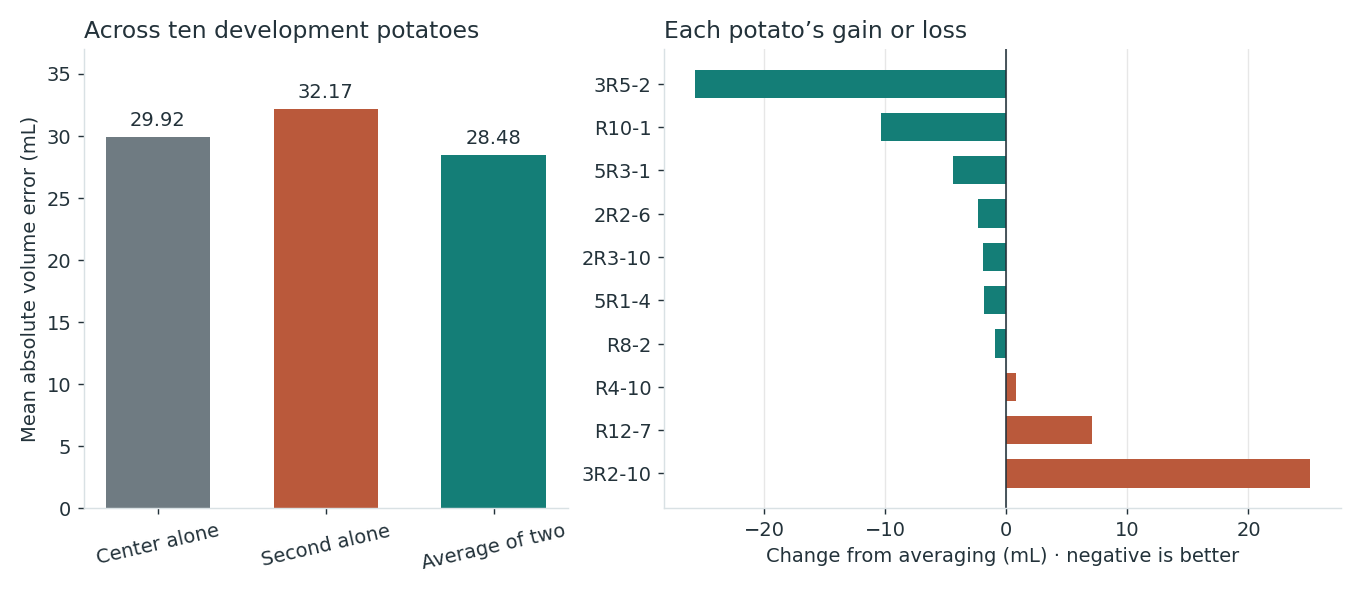

In [6]:
two_frame = result("corepp_two_frame_volume/results.json")
volumes = records(STUDY + "corepp_two_frame_volume/per_potato.csv")
vrows = sorted(volumes, key=lambda row: float(row["average_minus_center_error_ml"]))
fig, (left, right) = plt.subplots(1, 2, figsize=(10.4, 4.4), layout="constrained",
                                  gridspec_kw={"width_ratios": [1, 1.4]})
names = ["Center alone", "Second alone", "Average of two"]
means = [two_frame["mean_absolute_error_ml"][k] for k in ("center", "second", "average")]
bars = left.bar(names, means, color=[GRAY, ORANGE, TEAL], width=.62)
left.bar_label(bars, labels=[f"{v:.2f}" for v in means], padding=4)
left.set_ylim(0, 37)
left.tick_params(axis="x", labelrotation=13)
left.set_ylabel("Mean absolute volume error (mL)")
left.set_title("Across ten development potatoes", loc="left")
signed_bars(right, [row["tuber"] for row in vrows],
            [float(row["average_minus_center_error_ml"]) for row in vrows],
            "Change from averaging (mL) · negative is better")
right.set_title("Each potato’s gain or loss", loc="left")
plot(fig, "Mean volume error for center, second and averaged estimates and paired per-potato changes")

### Which two potatoes should get a rescan?

We compared two different decisions with an exact two-rescan budget. The first asked whether the eight scans accepted without a rescan would have lower **surface error**. The second used both available predictions for the flagged pair and measured **volume error across all ten**.

- **Appearance sensitivity** was worse than random for selecting the eight accepted scans. It beat depth rejection on that endpoint.
- **Ellipsoid disagreement** gave **31.99 mL** mean error, above center alone (**29.92**), random (**29.63**) and choosing by center-estimated size (**29.86**). One flagged potato gained **4.40 mL** and the other lost **25.10 mL**.
- The **hindsight oracle** shows the available upside for those two saved frames. It uses the reference outcomes to select the pair.

[Appearance screen](studies/regional_shape_v1/corepp_rescan_screen/report.md) · [Volume rescan policy and all 45 pairs](studies/regional_shape_v1/corepp_volume_rescan/report.md)

Surface-error screen,Mean error of eight accepted scans (mm)
Uniform random,3.0225
Exposure sensitivity,3.0981
Depth rejection,3.2021


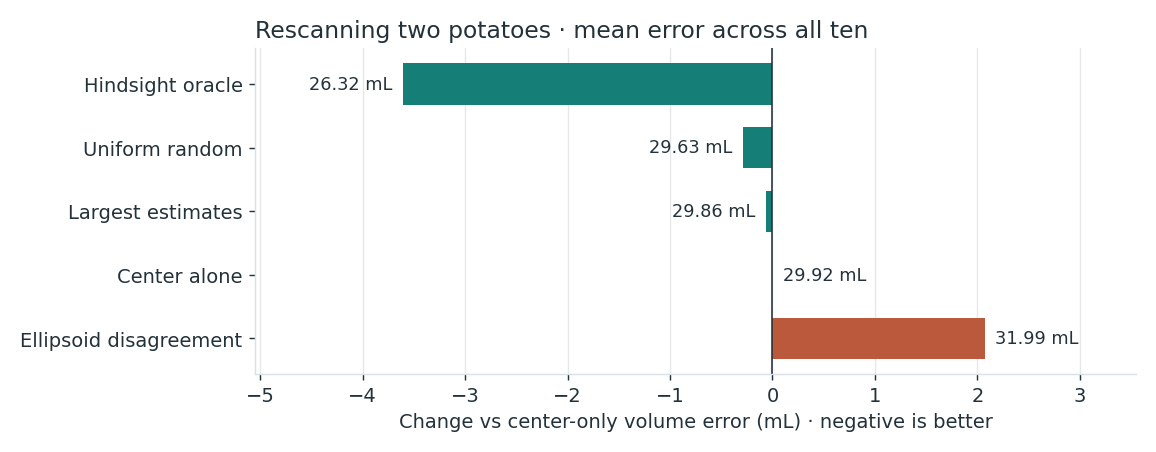

In [7]:
appearance = result("corepp_rescan_screen/results.json")
policy = result("corepp_volume_rescan/results.json")["policies"]
compact_table(
    ["Surface-error screen", "Mean error of eight accepted scans (mm)"],
    [(label, f"{value:.4f}") for label, value in [
        ("Uniform random", appearance["random"]["accepted_mean_mm"]),
        ("Exposure sensitivity", appearance["rules"]["sensitivity"]["accepted_mean_mm"]),
        ("Depth rejection", appearance["rules"]["depth"]["accepted_mean_mm"]),
    ]]
)
changes = [("Hindsight oracle", "oracle"), ("Uniform random", "random"), ("Largest estimates", "size"),
           ("Center alone", "center_all"), ("Ellipsoid disagreement", "disagreement")]
base = policy["center_all"]["mae_ml"]
fig, ax = plt.subplots(figsize=(8.8, 3.3), layout="constrained")
diff = [policy[k]["mae_ml"]-base for _, k in changes]
signed_bars(ax, [label for label, _ in changes], diff, "Change vs center-only volume error (mL) · negative is better")
for i, (_, key) in enumerate(changes):
    value = diff[i]
    ax.text(value + (.10 if value >= 0 else -.10), i, f"{policy[key]['mae_ml']:.2f} mL",
            ha="left" if value >= 0 else "right", va="center", fontsize=10)
ax.set_xlim(-5.05, 3.55)
ax.set_title("Rescanning two potatoes · mean error across all ten", loc="left")
plot(fig, "Ellipsoid disagreement ranked last among volume rescan policies")

## 6. Did a second RGB model respond the same way?

The feasibility audit found that the original CoRe potato baseline lacked a separate public checkpoint in the authors’ listing. TCoRe consumes RGB in its RealSense path, but the released implementation hard-codes CUDA. We verified the independently trained **TripoSR** checkpoint on CPU with an unchanged potato frame. Both meshes were byte-identical and the pin survived preprocessing. The native mesh has normalized units, so the fixed approximate millimeter scale came from the unchanged scan’s depth and camera intrinsics. The predicted shape was unusually thin along the viewing axis.

With a TripoSR-specific exact match covering **2,079 input pixels** at each site, **peel moved the predicted surface farther** on frame **2R1-10 / 364**. CoRe++ favored the pin on that same frame. This is a direction comparison from two one-frame pilots.

[Candidate and CPU feasibility audit](studies/regional_shape_v1/corepp_cross_model/report.md) · [TripoSR pilot](studies/regional_shape_v1/triposr_pin_pilot/report.md)

TripoSR contrast,Mean displacement (native units),Approx. displacement (mm)
Pin edit,0.00258275,0.2145
Peel edit,0.00406455,0.3376
Pin minus peel,-0.00148180,-0.1231


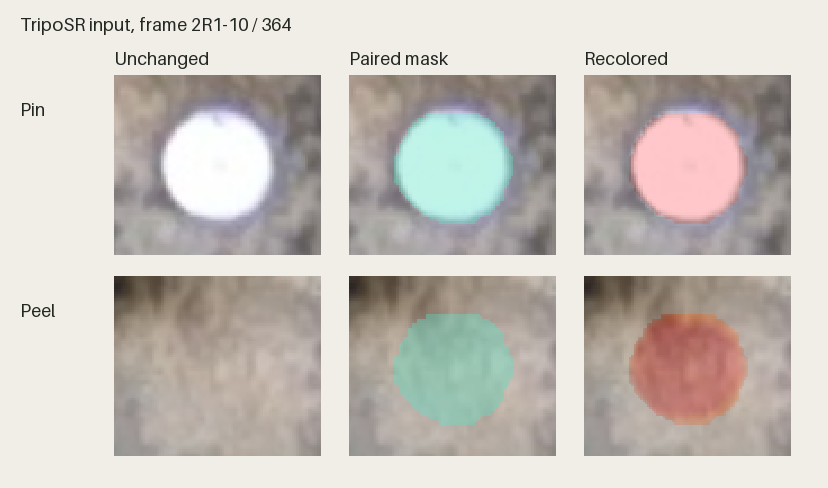

In [8]:
tripo = result("triposr_pin_pilot/results.json")
values = []
for label, key in (("Pin edit", "pin"), ("Peel edit", "peel")):
    displacement = tripo["conditions"][key]["displacement"]
    values.append((label, displacement["native_units"]["mean"], displacement["approx_mm"]["mean"]))
values.append(("Pin minus peel", tripo["pin_minus_peel"]["native_units"], tripo["pin_minus_peel"]["approx_mm"]))
compact_table(
    ["TripoSR contrast", "Mean displacement (native units)", "Approx. displacement (mm)"],
    [(label, f"{native:.8f}", f"{value:+.4f}" if label == "Pin minus peel" else f"{value:.4f}")
     for label, native, value in values]
)
archived_figure(STUDY + "triposr_pin_pilot/paired_crops.png",
                "Matched pin and peel intervention on the same TripoSR input frame")

## What this project established

- We built a reproducible CPU workflow that tests where geometry assumptions help and where they fail.
- On fresh CoRe++ test potatoes, changing the pin generally moved the surface farther than an equally strong peel edit. The fresh estimate remains descriptive under the group rule.
- On development potatoes, sensitivity, reference accuracy, and the benefit of a second frame were different outcomes. Both tested rescan selection rules fell short of random on their respective endpoints.

**Still open.** Whether the model responds specifically to marker identity, what physical marker removal would do to accuracy, and whether the one-frame TripoSR reversal repeats.

## Appendix · Study index and detailed tables

Read the source reports for complete per-seed, per-potato, and uncertainty records. The tables below are generated from the archived results. The notebook only loads result summaries, derived tables, and saved figures.

| Evidence block | Archive |
|---|---|
| CPU baseline design and public potato demo | [Methodology](docs/methodology.md) · [Feasibility](docs/feasibility.md) · [Experiment log](docs/experiment_log.md) |
| Height and depth repair | [Height robustness](docs/height_development_report.md) · [Local support](docs/spatial_confidence_report.md) · [Multiscale](docs/multiscale_confidence_report.md) · [Body detail](studies/body_detail_v1/results.md) |
| Laboratory sweet peppers and registered potato lobes | [Bonn holdout](docs/bonn_real_v1_report.md) · [Potato lobe pilot](studies/real_lobes_v1/fresh_pilot_report.md) |
| Real-potato underside reconstruction | [Development](studies/regional_shape_v1/results.md) · [Weight selection](studies/regional_shape_v1/reflection_weight_report.md) · [Reflection replication](studies/regional_shape_v1/replication_report.md) |
| Height corrections and calibration | [Reference diagnostic](studies/regional_shape_v1/vertical_offset_report.md) · [Scan-only development](studies/regional_shape_v1/support_offset_report.md) · [Separate-cohort test](studies/regional_shape_v1/support_offset_confirmation_report.md) · [Audit](studies/regional_shape_v1/calibration_data_audit.md) |
| CoRe++ color interventions | [CPU audit](studies/regional_shape_v1/corepp_cpu_audit.md) · [Pilot](studies/regional_shape_v1/corepp_pin_pilot/report.md) · [Ten-potato development](studies/regional_shape_v1/corepp_pin_multituber/report.md) · [Grid check](studies/regional_shape_v1/corepp_pin_grid_boundary/report.md) · [29 fresh potatoes](studies/regional_shape_v1/corepp_pin_confirmation/report.md) · [Reference accuracy](studies/regional_shape_v1/corepp_pin_accuracy/report.md) |
| Pixel transplantation | [Swap pilot](studies/regional_shape_v1/corepp_pin_swap_pilot/report.md) · [Swap replication](studies/regional_shape_v1/corepp_pin_swap_replication/report.md) |
| Need for a second frame | [Single-scan appearance screen](studies/regional_shape_v1/corepp_rescan_screen/report.md) · [Two-frame volumes](studies/regional_shape_v1/corepp_two_frame_volume/report.md) · [Fixed-budget volume policy](studies/regional_shape_v1/corepp_volume_rescan/report.md) |
| Independent RGB model | [Feasibility audit](studies/regional_shape_v1/corepp_cross_model/report.md) · [TripoSR matched pilot](studies/regional_shape_v1/triposr_pin_pilot/report.md) |

In [9]:
def evidence_table(data, title, columns):
    headers = [title for _, title, _ in columns]
    rows = [[transform(row[key]) for key, _, transform in columns] for row in data]
    compact_table(headers, rows, folded=f"{title} ({len(data)} rows)")


identity = str
mm = lambda v: f"{float(v):.3f}"
signed = lambda v: f"{float(v):+.3f}"
ml = lambda v: f"{float(v):.2f}"

evidence_table(fresh, "CoRe++ fresh-potato sensitivity", [
    ("potato", "Potato", identity), ("cultivar", "Cultivar", identity),
    ("primary_mm", "Pin − mean peel (mm)", signed), ("pin_minus_strongest_mm", "Pin − strongest peel (mm)", signed),
])
evidence_table(records(STUDY+"corepp_pin_accuracy/per_potato.csv"), "CoRe++ development reference accuracy", [
    ("potato", "Potato", identity), ("original_error_median_mm", "Original error (mm)", mm),
    ("pin_displacement_median_mm", "Pin movement (mm)", mm), ("pin_change_mm", "Signed error change (mm)", signed),
])
evidence_table(swap, "CoRe++ swap replication", [
    ("potato", "Potato", identity), ("endpoint_mm", "Shift (mm)", signed),
    ("n_pilot_reversals", "Pilot-direction reversals", identity),
    ("n_opposite_reversals", "Opposite reversals", identity),
])
evidence_table(records(STUDY+"corepp_rescan_screen/per_potato.csv"), "Single-frame appearance and depth scores", [
    ("potato", "Potato", identity), ("original_error_median_mm", "Original error (mm)", mm),
    ("sensitivity_mm", "Appearance sensitivity (mm)", mm),
    ("depth_rejected_fraction", "Depth rejected", lambda v: f"{float(v):.1%}"),
    ("sensitivity_flagged", "Flagged by sensitivity", identity), ("depth_flagged", "Flagged by depth", identity),
])
evidence_table(volumes, "Two-frame volume estimates", [
    ("tuber", "Potato", identity), ("center_frame", "Center frame", identity), ("second_frame", "Second frame", identity),
    ("drainage_ml", "Drainage (mL)", ml), ("center_ml", "Center (mL)", ml),
    ("second_ml", "Second (mL)", ml), ("average_ml", "Average (mL)", ml),
    ("average_minus_center_error_ml", "Change in error (mL)", signed),
])
evidence_table(records(STUDY+"corepp_volume_rescan/per_potato.csv"), "Two-rescan volume decision", [
    ("tuber", "Potato", identity), ("disagreement_ml", "First-frame disagreement (mL)", ml),
    ("disagreement_flagged", "Flagged by disagreement", identity),
    ("center_error_ml", "Center error (mL)", ml), ("average_error_ml", "Average error (mL)", ml),
    ("rescan_improvement_ml", "Rescan gain (mL)", signed),
])

Potato,Cultivar,Pin − mean peel (mm),Pin − strongest peel (mm)
R12-4,Sayaka,+0.022,+0.002
4R9-3,Sayaka,-0.957,-1.410
3R2-3,Sayaka,-1.035,-1.363
2R3-9,Kitahime,+1.233,+1.229
5R2-7,Corolle,+0.000,+0.000
R12-5,Sayaka,+1.087,+1.041
4R9-8,Sayaka,+0.038,+0.026
3R2-6,Sayaka,+0.241,+0.185
2R3-2,Kitahime,+1.075,+1.062
R12-6,Sayaka,+1.013,+0.933


Potato,Original error (mm),Pin movement (mm),Signed error change (mm)
5R1-4,4.739,0.076,-0.019
5R3-1,3.616,0.088,+0.031
2R2-6,3.681,0.801,-0.449
2R3-10,3.814,1.213,-0.711
R4-10,2.093,0.020,+0.000
R8-2,1.825,1.840,+0.215
R10-1,2.502,0.327,-0.134
R12-7,2.700,0.126,-0.028
3R2-10,2.740,0.647,+0.253
3R5-2,2.515,2.019,-0.435


Potato,Shift (mm),Pilot-direction reversals,Opposite reversals
3R5-2,+4.283,3,0
R8-2,+2.691,3,0
2R3-10,+1.871,3,0
2R2-6,+1.217,3,0
R10-1,+0.530,3,0
3R2-10,+0.514,2,0
5R3-1,+0.144,3,0
R12-7,+0.123,3,0
R4-10,+0.032,1,0
5R1-4,-0.217,0,3


Potato,Original error (mm),Appearance sensitivity (mm),Depth rejected,Flagged by sensitivity,Flagged by depth
5R1-4,4.739,0.288,7.0%,False,False
5R3-1,3.616,0.124,11.2%,False,False
2R2-6,3.681,0.235,10.4%,False,False
2R3-10,3.814,0.202,10.0%,False,False
R4-10,2.093,0.178,14.2%,False,True
R8-2,1.825,0.196,8.8%,False,False
R10-1,2.502,0.294,6.8%,False,False
R12-7,2.700,0.457,12.6%,True,False
3R2-10,2.740,0.419,12.9%,True,False
3R5-2,2.515,0.207,13.8%,False,True


Potato,Center frame,Second frame,Drainage (mL),Center (mL),Second (mL),Average (mL),Change in error (mL)
5R1-4,362,240,200.00,185.57,189.33,187.45,-1.875
5R3-1,360,201,60.00,90.68,81.88,86.28,-4.400
2R2-6,358,206,105.00,144.93,140.29,142.61,-2.318
2R3-10,363,208,220.00,151.30,155.19,153.24,-1.945
R4-10,352,211,90.00,91.12,92.80,91.96,+0.841
R8-2,350,206,55.00,73.23,71.44,72.33,-0.894
R10-1,362,212,200.00,162.40,183.05,172.73,-10.324
R12-7,353,208,250.00,266.77,280.98,273.87,+7.107
3R2-10,367,227,310.00,356.01,406.21,381.11,+25.099
3R5-2,359,230,320.00,294.23,345.68,319.96,-25.727


Potato,First-frame disagreement (mL),Flagged by disagreement,Center error (mL),Average error (mL),Rescan gain (mL)
5R1-4,9.69,False,14.43,12.55,+1.875
5R3-1,176.62,True,30.68,26.28,+4.400
2R2-6,27.05,False,39.93,37.61,+2.318
2R3-10,21.56,False,68.70,66.76,+1.945
R4-10,22.56,False,1.12,1.96,-0.841
R8-2,12.88,False,18.23,17.33,+0.894
R10-1,21.33,False,37.60,27.27,+10.324
R12-7,49.15,False,16.77,23.87,-7.107
3R2-10,97.24,True,46.01,71.11,-25.099
3R5-2,3.51,False,25.77,0.04,+25.727


### Additional demonstration figures

The baseline reconstruction, depth-repair checks, regional error maps, original color intervention, example swap, and paired conveyor crops are available below. Each pair of conveyor crops uses the same display scale.

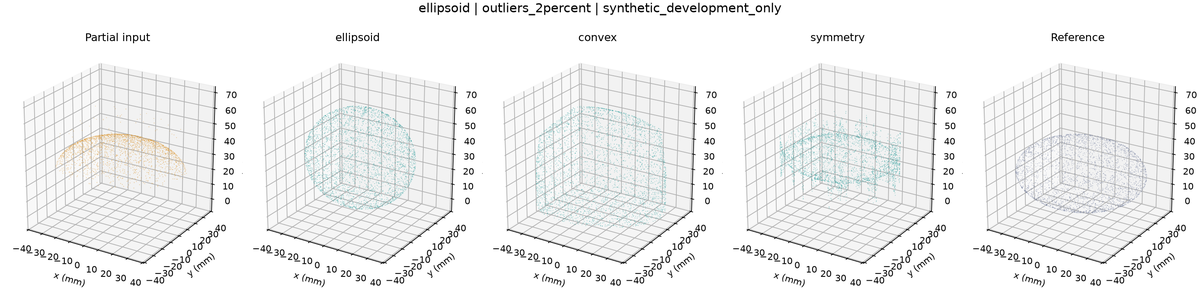

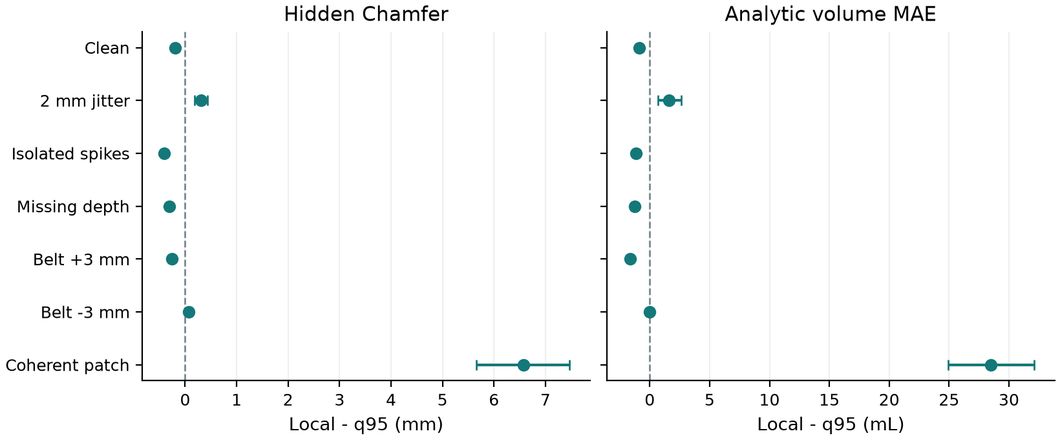

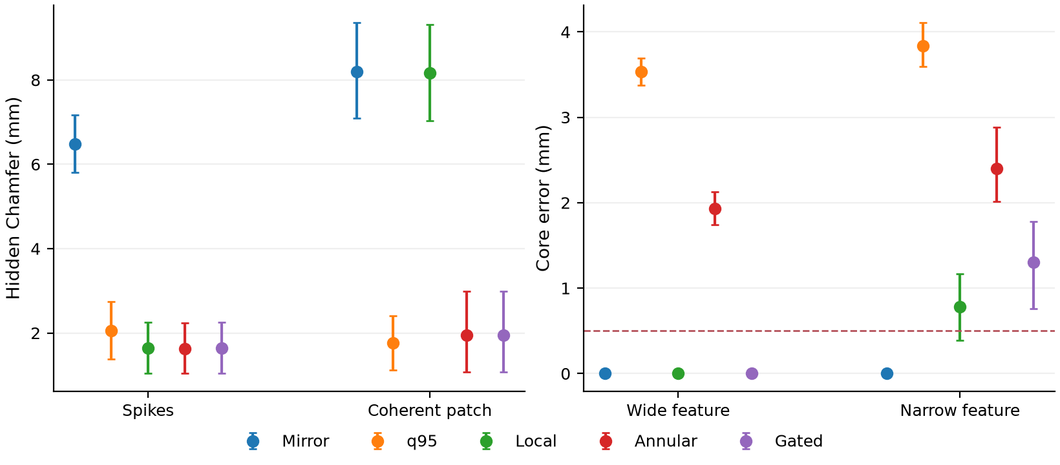

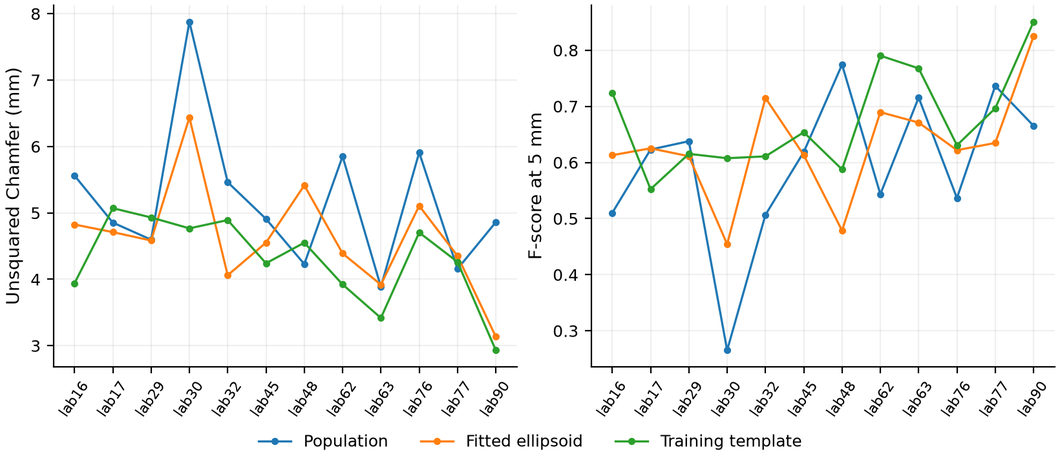

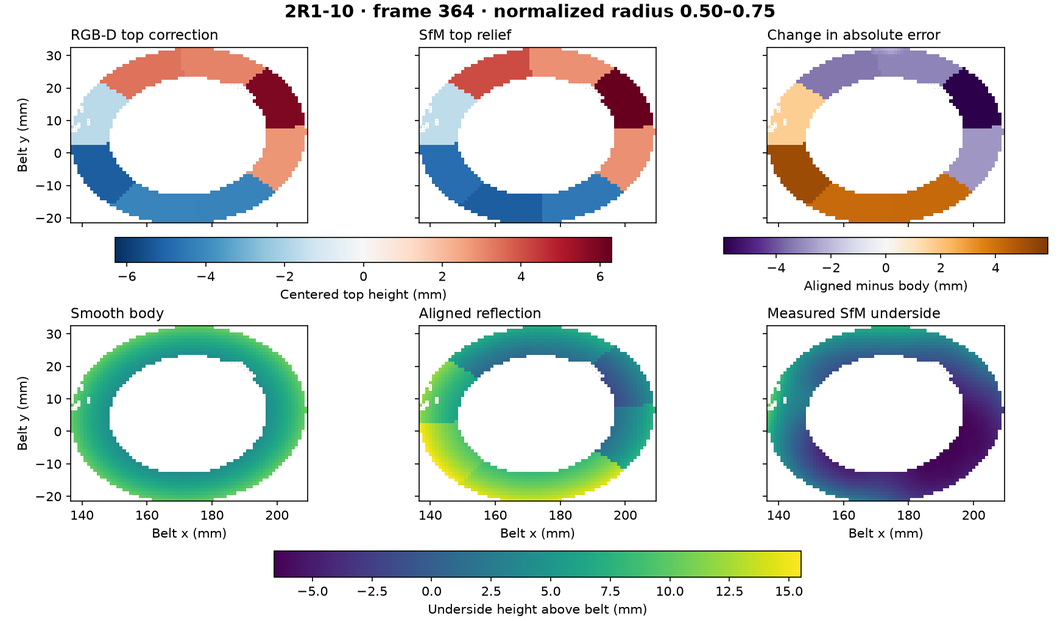

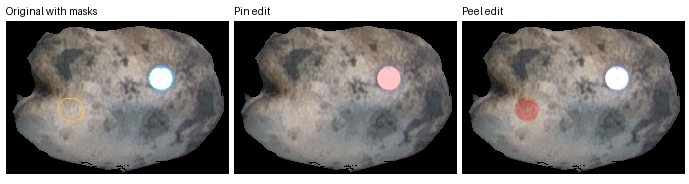

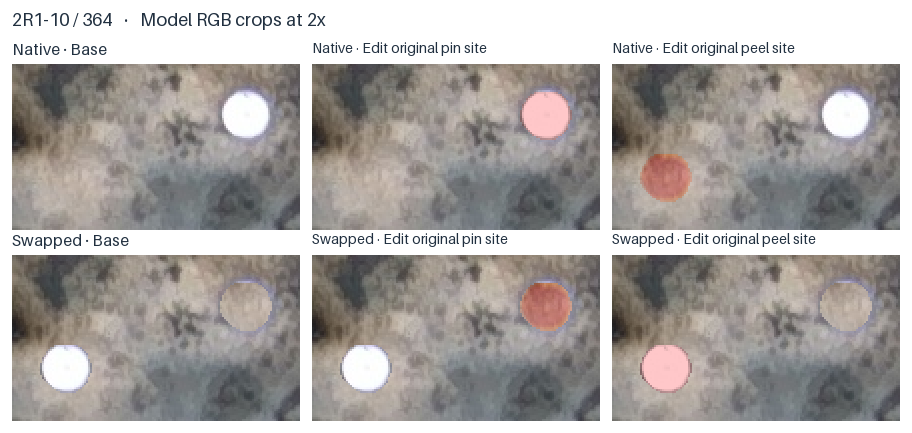

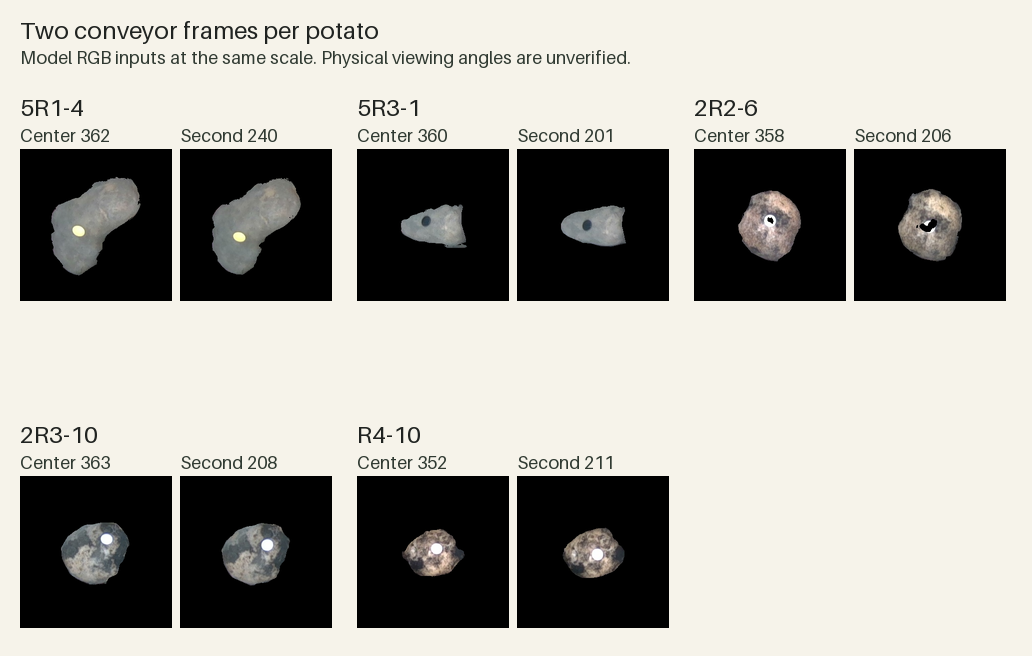

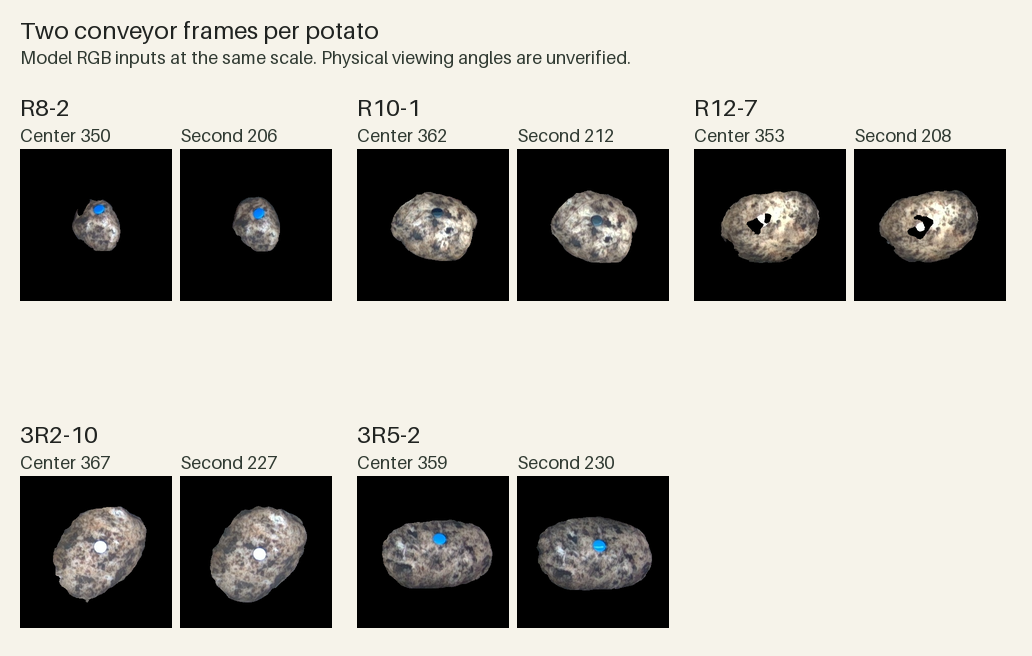

In [10]:
archived_figure("outputs/synthetic_study_v1/ellipsoid/outliers_2percent/comparison.png",
                "Partial synthetic potato scan, three classical 3D completions, and the complete reference", max_width=1200)
archived_figure("course/figures/spatial_confirmation.png", "Frozen local depth repair criteria on synthetic families")
archived_figure("course/figures/multiscale_tradeoffs.png", "Improvement on coherent artifacts and loss of real narrow features")
archived_figure("course/figures/bonn_objects.png", "Laboratory sweet-pepper holdout results")
archived_figure(STUDY+"example.png", "A registered potato’s observed top, predicted underside and reference underside")
archived_figure(STUDY+"corepp_pin_pilot/masks_and_edits.png", "CoRe++ input crop with the matched pin and peel recolorings")
archived_figure(STUDY+"corepp_pin_swap_pilot/native_swapped_crops.png", "Native and swapped CoRe++ pilot crops")
for page in (1, 2):
    archived_figure(STUDY+f"corepp_two_frame_volume/paired_crops_{page}.png",
                    f"Center and second frame crops for five potatoes, page {page}")